<a href="https://colab.research.google.com/github/renatarebelato/Precificacao-Dinamica/blob/main/Precifica%C3%A7%C3%A3o_Din%C3%A2mica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# 1. CAMADA DE GUARDRAILS (Piso de Rentabilidade)
def calcular_preco_minimo(
    custo_produto: float,
    canal: str,
    imposto_pct: float = 0.12,
    margem_minima_pct: float = 0.08,
    frete_medio: float = 45.0
) -> float:
    taxas_canal = {
        "SITE_PROPRIO": 0.035,
        "MKT_3P": 0.16,
        "MKT_1P": 0.22
    }

    taxa_variavel = taxas_canal.get(canal.upper(), 0.15)
    divisor = 1 - (imposto_pct + taxa_variavel + margem_minima_pct)

    if divisor <= 0:
        raise ValueError("A soma das taxas e margem mínima ultrapassa 100%.")

    preco_piso = (custo_produto + frete_medio) / divisor
    return round(preco_piso, 2)


# 2. CAMADA DE REGRAS DE CONCORRÊNCIA E ESTOQUE
def aplicar_regra_concorrencia(
    preco_atual: float,
    preco_piso: float,
    canal: str,
    concorrentes: list[dict],
    estoque_dias: int
) -> tuple[float, str]:
    ativos = [c["preco"] for c in concorrentes if c.get("em_estoque", False)]
    menor_concorrente = min(ativos) if ativos else None

    fator_estoque = 1.0
    if estoque_dias < 10:
        fator_estoque = 1.04  # Estoque crítico (<10 dias): sobe 4%
    elif estoque_dias > 90:
        fator_estoque = 0.96  # Estoque alto (>90 dias): reduz 4%

    preco_alvo = preco_atual * fator_estoque
    motivo = "Manutenção / Ajuste de Estoque"

    if menor_concorrente:
        if canal == "MKT_3P":
            preco_alvo = (menor_concorrente - 0.10) * fator_estoque
            motivo = "Cobertura Buy Box 3P"
        elif canal == "SITE_PROPRIO":
            teto_competitivo = menor_concorrente * 1.02
            if preco_alvo > teto_competitivo:
                preco_alvo = teto_competitivo
                motivo = "Seguidor Seletivo D2C (+2% spread)"
        elif canal == "MKT_1P":
            preco_alvo = menor_concorrente
            motivo = "Paridade Sell-Out 1P"

    if preco_alvo < preco_piso:
        return preco_piso, f"Travado no Piso de Margem ({motivo})"

    return round(preco_alvo, 2), motivo


# 3. ORQUESTRADOR PRINCIPAL
def executar_motor_precificacao(df_skus: pd.DataFrame) -> pd.DataFrame:
    resultados = []

    for _, row in df_skus.iterrows():
        piso = calcular_preco_minimo(
            custo_produto=row["custo_unitario"],
            canal=row["canal"],
            frete_medio=row["frete_medio"]
        )

        preco_final, regra_aplicada = aplicar_regra_concorrencia(
            preco_atual=row["preco_atual"],
            preco_piso=piso,
            canal=row["canal"],
            concorrentes=row["concorrentes"],
            estoque_dias=row["cobertura_estoque_dias"]
        )

        resultados.append({
            "sku": row["sku"],
            "produto": row["produto_nome"],
            "canal": row["canal"],
            "estoque_dias": row["cobertura_estoque_dias"],
            "preco_anterior": row["preco_atual"],
            "preco_piso": piso,
            "preco_sugerido": preco_final,
            "variacao_pct": round(((preco_final / row["preco_atual"]) - 1) * 100, 2),
            "regra_aplicada": regra_aplicada
        })

    return pd.DataFrame(resultados)


# 4. BASE OPERACIONAL INTERNA (Cenários reais de e-commerce de eletrodomésticos)
catalogo_operacional = pd.DataFrame([
    # Cenário 1: GEL-001 (Produto Curva A em 3 canais diferentes)
    {
        "sku": "GEL-001", "produto_nome": "Geladeira Frost Free 375L", "canal": "SITE_PROPRIO",
        "custo_unitario": 1850.0, "frete_medio": 65.0, "preco_atual": 2899.90, "cobertura_estoque_dias": 45,
        "concorrentes": [{"nome": "Varejista A", "preco": 2799.00, "em_estoque": True}]
    },
    {
        "sku": "GEL-001", "produto_nome": "Geladeira Frost Free 375L", "canal": "MKT_3P",
        "custo_unitario": 1850.0, "frete_medio": 80.0, "preco_atual": 2899.90, "cobertura_estoque_dias": 45,
        "concorrentes": [{"nome": "Varejista A", "preco": 2799.00, "em_estoque": True}]
    },
    {
        "sku": "GEL-001", "produto_nome": "Geladeira Frost Free 375L", "canal": "MKT_1P",
        "custo_unitario": 1850.0, "frete_medio": 0.0, "preco_atual": 2899.90, "cobertura_estoque_dias": 45,
        "concorrentes": [{"nome": "Varejista B", "preco": 2849.00, "em_estoque": True}]
    },

    # Cenário 2: GEL-004 (Estoque crítico < 10 dias -> Sobe preço para proteger ruptura)
    {
        "sku": "GEL-004", "produto_nome": "Geladeira Multidoor 590L", "canal": "SITE_PROPRIO",
        "custo_unitario": 4100.0, "frete_medio": 110.0, "preco_atual": 6899.00, "cobertura_estoque_dias": 7,
        "concorrentes": [{"nome": "Varejista A", "preco": 6950.00, "em_estoque": True}]
    },

    # Cenário 3: GEL-008 (Concorrente sem estoque -> Ignora preço baixo e recupera margem)
    {
        "sku": "GEL-008", "produto_nome": "Geladeira Cycle Defrost 260L", "canal": "MKT_3P",
        "custo_unitario": 1150.0, "frete_medio": 70.0, "preco_atual": 1999.00, "cobertura_estoque_dias": 35,
        "concorrentes": [
            {"nome": "Varejista C (Ruptura)", "preco": 1750.00, "em_estoque": False},
            {"nome": "Varejista D (Ativo)", "preco": 2050.00, "em_estoque": True}
        ]
    },

    # Cenário 4: GEL-010 (Estoque encalhado > 90 dias -> Reduz preço para girar caixa)
    {
        "sku": "GEL-010", "produto_nome": "Frigobar Retrô 76L", "canal": "SITE_PROPRIO",
        "custo_unitario": 980.0, "frete_medio": 45.0, "preco_atual": 1699.00, "cobertura_estoque_dias": 115,
        "concorrentes": []
    }
])

df_resultado = executar_motor_precificacao(catalogo_operacional)
display(df_resultado)

,sku,produto,canal,estoque_dias,preco_anterior,preco_piso,preco_sugerido,variacao_pct,regra_aplicada
0,GEL-001,Geladeira Frost Free 375L,SITE_PROPRIO,45,2899.9,2503.27,2854.98,-1.55,Seguidor Seletivo D2C (+2% spread)
1,GEL-001,Geladeira Frost Free 375L,MKT_3P,45,2899.9,3015.63,3015.63,3.99,Travado no Piso de Margem (Cobertura Buy Box 3P)
2,GEL-001,Geladeira Frost Free 375L,MKT_1P,45,2899.9,3189.66,3189.66,9.99,Travado no Piso de Margem (Paridade Sell-Out 1P)
3,GEL-004,Geladeira Multidoor 590L,SITE_PROPRIO,7,6899.0,5503.27,7089.00,2.75,Seguidor Seletivo D2C (+2% spread)
4,GEL-008,Geladeira Cycle Defrost 260L,MKT_3P,35,1999.0,1906.25,2049.90,2.55,Cobertura Buy Box 3P
5,GEL-010,Frigobar Retrô 76L,SITE_PROPRIO,115,1699.0,1339.87,1631.04,-4.00,Manutenção / Ajuste de Estoque


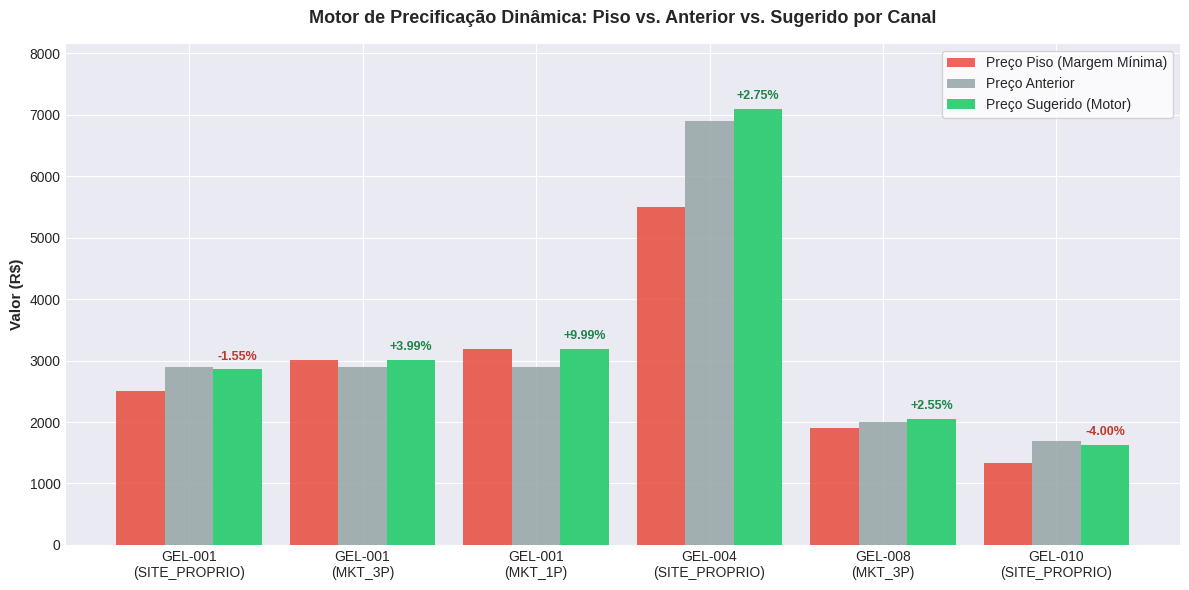

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Configura o estilo visual
plt.style.use('seaborn-v0_8-darkgrid')
fig, ax = plt.subplots(figsize=(12, 6))

# Cria rótulos combinando SKU + Canal
labels = df_resultado['sku'] + '\n(' + df_resultado['canal'] + ')'
x = np.arange(len(labels))
largura = 0.28

# Plota as 3 barras lado a lado
rects1 = ax.bar(x - largura, df_resultado['preco_piso'], largura, label='Preço Piso (Margem Mínima)', color='#e74c3c', alpha=0.85)
rects2 = ax.bar(x, df_resultado['preco_anterior'], largura, label='Preço Anterior', color='#95a5a6', alpha=0.85)
rects3 = ax.bar(x + largura, df_resultado['preco_sugerido'], largura, label='Preço Sugerido (Motor)', color='#2ecc71', alpha=0.95)

# Adiciona os rótulos de variação (%) acima das barras do Preço Sugerido
for i, rect in enumerate(rects3):
    altura = rect.get_height()
    var = df_resultado['variacao_pct'].iloc[i]
    sinal = "+" if var > 0 else ""
    cor_texto = '#1e8449' if var >= 0 else '#c0392b'

    ax.annotate(f"{sinal}{var:.2f}%",
                xy=(rect.get_x() + rect.get_width() / 2, altura),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold', color=cor_texto)

# Formatação do gráfico
ax.set_ylabel('Valor (R$)', fontsize=11, fontweight='bold')
ax.set_title('Motor de Precificação Dinâmica: Piso vs. Anterior vs. Sugerido por Canal', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.legend(frameon=True, facecolor='white', fontsize=10)
ax.set_ylim(0, df_resultado[['preco_piso', 'preco_anterior', 'preco_sugerido']].max().max() * 1.15)

plt.tight_layout()
plt.show()